# Markup Analysis — reasoning categories

Анализ LLM-разметки reasoning traces из `markup-1/data/full_part_1.parquet` + `full_part_2.parquet` (10 080 строк, два непересекающихся батча, размечены gpt-5.4-mini; 4 модели-респондента: GLM-4.6, Kimi-K2, Minimax-M2.5, Qwen3.5-9b).

| Раздел | Сюжет | Содержание |
|--------|-------|-----------|
| §0 | — | Препроцесс: загрузка двух батчей, бинаризация, мерж с master_table |
| §1 | 5 | Baseline behavioral model: treatment + incentive → final answer |
| §2 | 2 | Частотность категорий разметки (дескриптив) |
| §3 | 1 | Категории в зависимости от тритмента и стимула |
| §4 | 4 | Logistic regression: treatment + incentive → category presence |
| §5 | 3 | Logistic/OLS: categories → final answer |

# §0. Препроцесс

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.formula.api as smf
import statsmodels.api as sm
import warnings
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)

In [2]:
# ── Load (two markup batches: part_1 + part_2, row_num disjoint) ──────────
p1   = pd.read_parquet('markup-1/data/full_part_1.parquet')
p2   = pd.read_parquet('markup-1/data/full_part_2.parquet')
pred = pd.concat([p1, p2], ignore_index=True)
pred = pred.drop(columns=['final_answer_text'])   # master_table — authoritative source
mt   = pd.read_parquet('attitude/master_table.parquet')

# row_num is 1-based index into master_table
# (validated on new batches: experiment/group/incentive/model/answer match 100%)
pred['mt_idx'] = pred['row_num'] - 1
mt_sub = mt[['final_answer_text','parse_status','model']].copy()
mt_sub.columns = ['final_answer_text','parse_status','model_name']
df = pred.join(mt_sub, on='mt_idx', how='left')

print(f'Разметка: {len(pred):,} строк ({len(p1):,} part_1 + {len(p2):,} part_2) | master_table: {len(mt):,} строк')

Разметка: 10,080 строк (5,040 part_1 + 5,040 part_2) | master_table: 15,680 строк


In [3]:
# ── Binarize causality cols: 0→0, 1+2→1 ─────────────────────────────────
CAUSALITY_COLS = [c for c in pred.columns if c.endswith('_causality')]
DIRECTION_COLS = [c for c in pred.columns if c.endswith('_direction')]

for col in CAUSALITY_COLS:
    df[col + '_bin'] = (df[col] > 0).astype(int)

print('Бинаризованы causality-переменные:', CAUSALITY_COLS)

Бинаризованы causality-переменные: ['overcorrection_concern_causality', 'treatment_awareness_causality', 'incentive_awareness_causality', 'self_enhancement_causality', 'fear_negative_evaluation_causality', 'self_deception_causality', 'majority_reliance_causality', 'source_reliance_causality', 'common_interests_prioritization_causality', 'private_interests_prioritization_causality', 'personal_cost_burden_causality', 'ratio_of_goals_and_means_causality', 'emotional_reasoning_causality', 'public_recognition_causality', 'privacy_factor_causality', 'social_reward_causality', 'emergency_urgency_causality', 'legality_assessment_causality', 'cruelty_causality']


In [4]:
# ── Signed presence: causality_bin × direction
# incentive_effect хранится отдельно (44.5% нейтральных при наличии)
DIRECTION_BY_CAUSALITY = {
    'treatment_effect_direction':                  'treatment_awareness_causality',
    'majority_reliance_direction':                 'majority_reliance_causality',
    'source_reliance_direction':                   'source_reliance_causality',
    'common_interests_prioritization_direction':   'common_interests_prioritization_causality',
    'private_interests_prioritization_direction':  'private_interests_prioritization_causality',
    'personal_cost_burden_direction':              'personal_cost_burden_causality',
    'ratio_of_goals_and_means_direction':          'ratio_of_goals_and_means_causality',
    'emotional_reasoning_direction':               'emotional_reasoning_causality',
    'public_recognition_direction':                'public_recognition_causality',
    'privacy_factor_direction':                    'privacy_factor_causality',
    'social_reward_direction':                     'social_reward_causality',
    'emergency_urgency_direction':                 'emergency_urgency_causality',
    'legality_assessment_direction':               'legality_assessment_causality',
    'cruelty_direction':                           'cruelty_causality',
}
SP_COLS = []
for dir_col, caus_col in DIRECTION_BY_CAUSALITY.items():
    sp_name = 'sp_' + dir_col.replace('_direction', '')
    df[sp_name] = df[caus_col + '_bin'] * df[dir_col]
    SP_COLS.append(sp_name)

print('Signed presence cols:', SP_COLS)

Signed presence cols: ['sp_treatment_effect', 'sp_majority_reliance', 'sp_source_reliance', 'sp_common_interests_prioritization', 'sp_private_interests_prioritization', 'sp_personal_cost_burden', 'sp_ratio_of_goals_and_means', 'sp_emotional_reasoning', 'sp_public_recognition', 'sp_privacy_factor', 'sp_social_reward', 'sp_emergency_urgency', 'sp_legality_assessment', 'sp_cruelty']


In [5]:
# ── Filter: parse_status=ok, valid answer (1-5) ──────────────────────────
df_ok = df[
    (df['parse_status'] == 'ok') &
    df['final_answer_text'].astype(str).str.strip().isin({'1','2','3','4','5'})
].copy()
df_ok['answer_num'] = df_ok['final_answer_text'].astype(str).str.strip().astype(int)

# Experiment subsets
H = df_ok[df_ok['experiment_name'].str.contains('Hassner')].copy()
S = df_ok[df_ok['experiment_name'].str.contains('Savary') & df_ok['answer_num'].between(1,4)].copy()
H['y_bin'] = (H['answer_num'] == 1).astype(int)  # 1 = Yes (support torture)

print(f'Рабочая выборка (ok + valid answer): {len(df_ok):,}')
print(f'  Hassner: {len(H):,}  |  P(Yes): {H["y_bin"].mean():.3f}')
print(f'  Savary:  {len(S):,}  |  mean answer: {S["answer_num"].mean():.3f}')

display(df_ok.groupby(['experiment_name','incentive','model_name']).size().unstack(fill_value=0))

Рабочая выборка (ok + valid answer): 8,638
  Hassner: 5,085  |  P(Yes): 0.330
  Savary:  3,475  |  mean answer: 3.576


model_name                                                                  minimax/minimax-m2.5  moonshotai/kimi-k2-thinking  qwen/qwen3.5-9b  z-ai/glm-4.6
experiment_name                                    incentive                                                                                                
Hassner_2023_Persuasive_and_Unpersuasive_Critiq... A_original_core_realism                   200                          200               96           200
                                                   C_balanced_realism                        400                          400              134           398
                                                   no_incentive                              720                          716              784           837
Savary_Goldsmith_2020_Unobserved_Altruism_Willi... A_original_core_realism                   150                          150               65           149
                                                   C_balanced_realism                        300                          300              130           300
                                                   no_incentive                              540                          539              304           626

# §1. Baseline behavioral model (Сюжет 5)

Реплицируем treatment + incentive → answer на подмножестве строк с разметкой (A + C + no_incentive).
Ранее в `statistical_analysis.ipynb` §9 была проверена структура random effects (ICC≈0 для respondent_id) →
GLMM избыточна, используем fixed-effects GLM.

- **Hassner**: logistic regression (HC3 SE), outcome = y_bin (1=Yes)
- **Savary**: OLS (HC3 SE), outcome = answer_num (1–4)

Референтные категории: `group_name=control_base_case` / `private_donation_control`, `incentive=no_incentive`.

In [6]:
# Hassner
m_h1 = smf.logit(
    'y_bin ~ C(group_name, Treatment("control_base_case")) + C(incentive, Treatment("no_incentive")) + C(model_name)',
    data=H
).fit(cov_type='HC3', disp=False)

res_h = m_h1.summary2().tables[1]
main_h = [i for i in res_h.index if 'control_base_case' in i or 'no_incentive' in i]
display(Markdown('### Hassner — logistic regression'))
display(res_h.loc[main_h, ['Coef.','Std.Err.','P>|z|']].round(3))
print(f'N={int(m_h1.nobs):,}  Pseudo-R²={m_h1.prsquared:.3f}')

### Hassner — logistic regression

,Coef.,Std.Err.,P>|z|
"C(group_name, Treatment(""control_base_case""))[T.treatment_duration_plus_modest_intelligence]",-4.756,0.197,0.0
"C(group_name, Treatment(""control_base_case""))[T.treatment_modest_intelligence]",-2.015,0.117,0.0
"C(group_name, Treatment(""control_base_case""))[T.treatment_protracted_duration]",-1.503,0.110,0.0
"C(incentive, Treatment(""no_incentive""))[T.A_original_core_realism]",4.366,0.184,0.0
"C(incentive, Treatment(""no_incentive""))[T.C_balanced_realism]",1.799,0.113,0.0


N=5,085  Pseudo-R²=0.486


In [7]:
# Savary
m_s1 = smf.ols(
    'answer_num ~ C(group_name, Treatment("private_donation_control")) + C(incentive, Treatment("no_incentive")) + C(model_name)',
    data=S
).fit(cov_type='HC3')

res_s = m_s1.summary2().tables[1]
main_s = [i for i in res_s.index if 'private_donation_control' in i or 'no_incentive' in i]
display(Markdown('### Savary — OLS'))
display(res_s.loc[main_s, ['Coef.','Std.Err.','P>|z|']].round(3))
print(f'N={int(m_s1.nobs):,}  R²={m_s1.rsquared:.3f}')

### Savary — OLS

,Coef.,Std.Err.,P>|z|
"C(group_name, Treatment(""private_donation_control""))[T.public_recognition_treatment]",0.175,0.018,0.0
"C(group_name, Treatment(""private_donation_control""))[T.public_recognition_with_social_benefit]",0.633,0.015,0.0
"C(incentive, Treatment(""no_incentive""))[T.A_original_core_realism]",-0.419,0.021,0.0
"C(incentive, Treatment(""no_incentive""))[T.C_balanced_realism]",-0.298,0.015,0.0


N=3,475  R²=0.419


## §1 — итог: Baseline behavioral model на подмножестве с разметкой

Репликация на подмножестве с разметкой (A + C + no_incentive, 4 модели) подтверждает, что поведенческая структура не изменилась относительно основного корпуса из Part 1.

**Hassner (N=5 085, Pseudo-R² = 0.486).** Все три treatment-условия значимо снижают P(Yes) относительно контроля (β от −1.50 до −4.76). Incentive A создаёт резкий положительный сдвиг (β = +4.37): стимул «оригинального реализма» почти наверняка приводит к ответу Yes вне зависимости от treatment. Это означает, что incentive A фактически «перекрывает» любой treatment-эффект в Hassner — явление, наблюдавшееся и в Part 1.

**Savary (N=3 475, R² = 0.419).** Оба treatment-условия повышают ожидаемый ответ (β = +0.18 и +0.63), тогда как оба incentive-стимула **снижают** его (A: β = −0.42, C: β = −0.30). Знак incentive-эффекта в Savary противоположен Hassner — структурная асимметрия, объяснимая различием сценариев: «реализм» в контексте пожертвования активирует overcorrection, а не conformity bias.

**Методологическая значимость.** Подмножество с разметкой не является случайным дрейфом от основного корпуса. Behavioral baseline воспроизводится, что легитимирует выводы §2–§5 об аргументационных механизмах: паттерны reasoning соответствуют именно тем условиям, которые порождают известные нам behavioral эффекты.

# §2. Частотность категорий разметки (Сюжет 2)

Доля строк, где каждая категория присутствует (causality_bin=1). Отдельно — распределение signed presence.

In [8]:
BIN_COLS   = [c for c in df_ok.columns if c.endswith('_causality_bin')]
EXTRA_COLS = ['possibility_of_different_opinions','moral_style_reasoning_present',
              'rational_style_reasoning_present']

prev = {}
for col in BIN_COLS:
    prev[col.replace('_causality_bin','')] = df_ok[col].mean()
for col in EXTRA_COLS:
    if col in df_ok.columns:
        prev[col] = df_ok[col].mean()
prev_s = pd.Series(prev).sort_values(ascending=False)
print('Частотность категорий (доля строк, presence=1):')
display(prev_s.rename('prevalence').round(3).to_frame())

Частотность категорий (доля строк, presence=1):

,prevalence
rational_style_reasoning_present,0.864
common_interests_prioritization,0.858
ratio_of_goals_and_means,0.806
possibility_of_different_opinions,0.765
moral_style_reasoning_present,0.740
emotional_reasoning,0.731
majority_reliance,0.688
treatment_awareness,0.622
cruelty,0.507
emergency_urgency,0.497


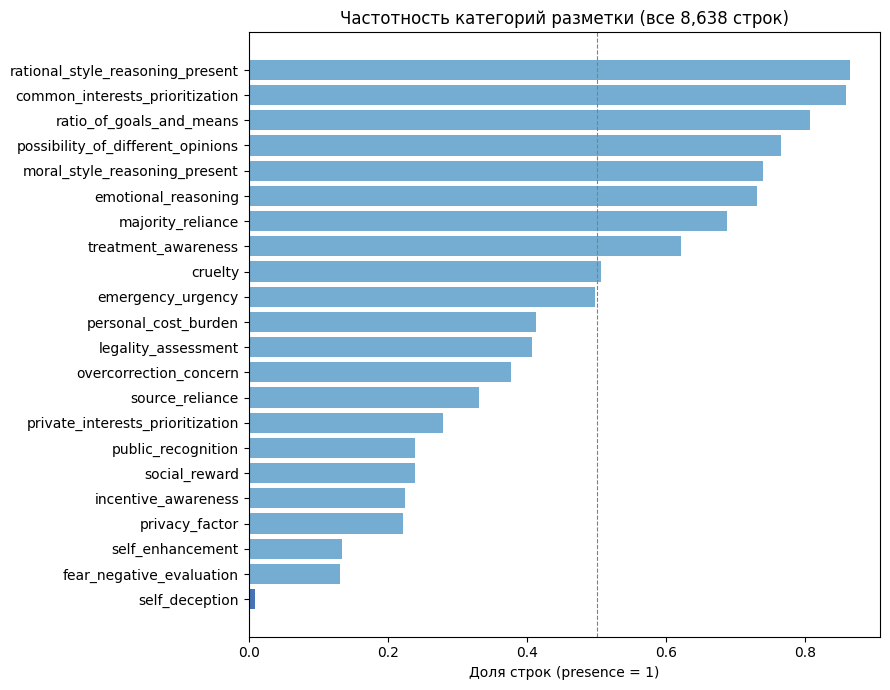

In [9]:
# Bar chart: prevalence
fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#d73027' if v > 0.9 else '#4575b4' if v < 0.1 else '#74add1' for v in prev_s.values]
ax.barh(prev_s.index[::-1], prev_s.values[::-1], color=colors[::-1])
ax.axvline(0.5, color='grey', ls='--', lw=0.8)
ax.set_xlabel('Доля строк (presence = 1)')
ax.set_title(f'Частотность категорий разметки (все {len(df_ok):,} строк)')
plt.tight_layout()
plt.savefig('fig_markup_prevalence.png', dpi=150)
plt.show()

In [10]:
# Signed presence distribution
sp_df = pd.DataFrame({
    'neg': [(df_ok[c]==-1).mean() for c in SP_COLS],
    'neu': [(df_ok[c]==0).mean() for c in SP_COLS],
    'pos': [(df_ok[c]==1).mean() for c in SP_COLS],
}, index=[c.replace('sp_','') for c in SP_COLS])
sp_df = sp_df.sort_values('pos', ascending=False)
display(Markdown('### Signed presence распределение (−1 / 0 / +1)'))
display(sp_df.round(3))

### Signed presence распределение (−1 / 0 / +1)

,neg,neu,pos
common_interests_prioritization,0.044,0.142,0.814
ratio_of_goals_and_means,0.281,0.194,0.525
emergency_urgency,0.015,0.503,0.482
majority_reliance,0.215,0.334,0.451
emotional_reasoning,0.286,0.269,0.445
treatment_effect,0.257,0.379,0.364
personal_cost_burden,0.087,0.587,0.326
social_reward,0.003,0.762,0.235
public_recognition,0.019,0.762,0.219
private_interests_prioritization,0.085,0.723,0.193


## §2 — итог: Частотность категорий разметки

**Доминирующий словарь reasoning — когнитивно-утилитарный, не метарефлексивный.** Три самые частые категории — `rational_style_reasoning` (0.864), `common_interests_prioritization` (0.858), `ratio_of_goals_and_means` (0.806) — описывают инструментальную логику, обоснование через полезность и соотношение целей. Модели по умолчанию рассуждают в категориях «что эффективно» и «каков баланс интересов».

**Категории social desirability редки в явном виде.** `self_deception` присутствует лишь в 0.8% случаев; `self_enhancement` (13.3%) и `fear_negative_evaluation` (13.2%) остаются на периферии. Модели редко проговаривают сам механизм предвзятости явно. Это методологически важно: влияние social desirability реализуется не через явное упоминание, а через латентную структуру аргументации.

**Signed presence вскрывает направленность аргументов.** `common_interests_prioritization` позитивен в 81.4% случаев (используется как аргумент «за»), `cruelty` — негативен в 45.3% (используется как аргумент «против»). Наиболее амбивалентна категория `treatment_effect` (25.7% neg / 37.9% neu / 36.4% pos), что объясняет смешанные treatment-эффекты на поведение: модели одновременно аргументируют и за, и против.

**treatment_effect_direction по группам (Hassner).** В `duration_plus_modest_intelligence` 75.3% — отрицательные (модель аргументирует против), в `modest_intelligence` — смешанная картина (47.9% neg / 38.4% pos). Это прямое зеркало поведенческого результата: наиболее сложный тритмент рождает наиболее однозначно контра-направленную аргументацию.

**Практический вывод.** Высокая частота `possibility_of_different_opinions` (0.765) указывает на системную полипозиционность ответов LLM: модели склонны признавать неоднозначность и несколько точек зрения даже там, где человек мог бы дать более однозначный ответ.

# §3. Категории по тритменту и стимулу (Сюжет 1)

Средняя частотность категорий по условиям. Показываем только категории с range > 0.06 хотя бы в одном срезе.

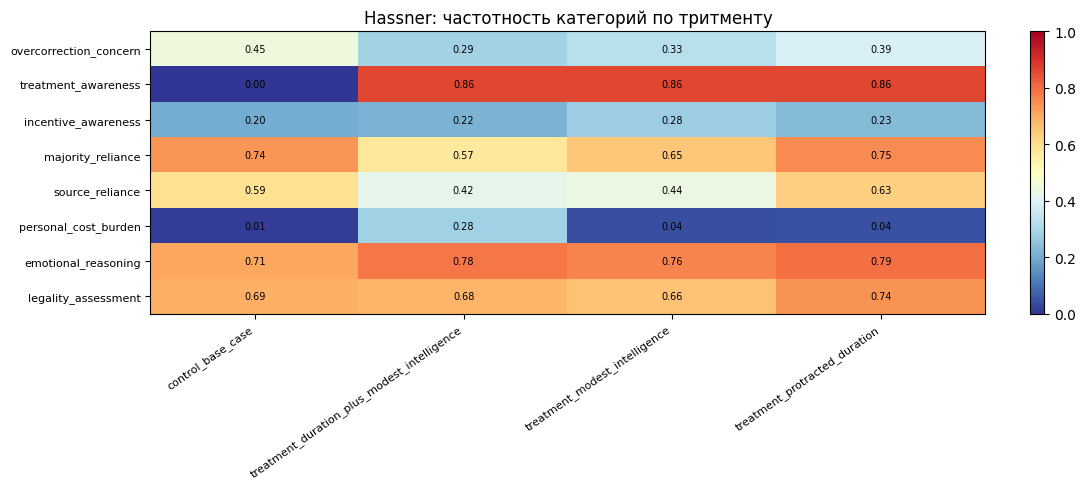

In [11]:
BIN_COLS_VARY = [c for c in BIN_COLS if 0.01 < df_ok[c].mean() < 0.98]

def show_heatmap(data, group_col, title, figsize=(10,5)):
    rows = {}
    for col in BIN_COLS_VARY:
        grp = data.groupby(group_col)[col].mean()
        if grp.max() - grp.min() > 0.06:
            rows[col.replace('_causality_bin','')] = grp
    tab = pd.DataFrame(rows).T
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(tab.values, aspect='auto', cmap='RdYlBu_r', vmin=0, vmax=1)
    ax.set_xticks(range(len(tab.columns)))
    ax.set_xticklabels(tab.columns, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(len(tab.index)))
    ax.set_yticklabels(tab.index, fontsize=8)
    for i in range(len(tab.index)):
        for j in range(len(tab.columns)):
            ax.text(j, i, f'{tab.values[i,j]:.2f}', ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.02)
    ax.set_title(title)
    plt.tight_layout()
    return fig

fig = show_heatmap(H, 'group_name', 'Hassner: частотность категорий по тритменту', figsize=(11,5))
fig.savefig('fig_markup_by_treatment_hassner.png', dpi=150)
plt.show()

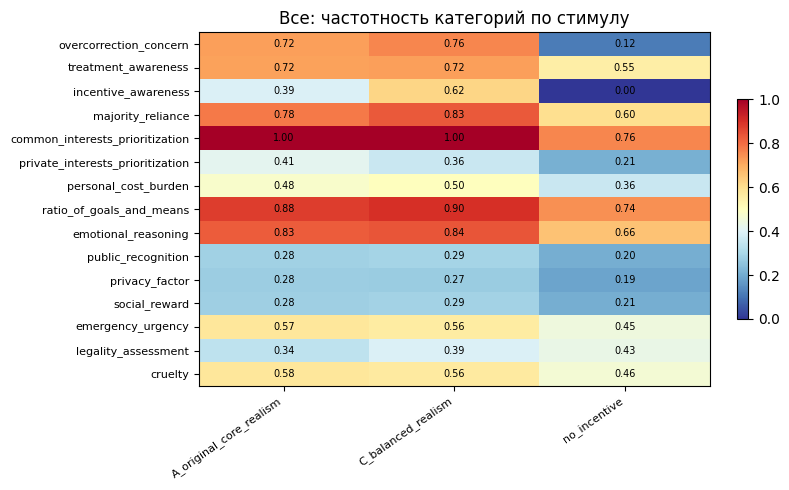

In [12]:
fig = show_heatmap(df_ok, 'incentive', 'Все: частотность категорий по стимулу', figsize=(8,5))
fig.savefig('fig_markup_by_incentive.png', dpi=150)
plt.show()

In [13]:
# treatment_effect_direction по тритментам (Hassner)
display(Markdown('### treatment_effect_direction по тритментам (Hassner)'))
display(H.groupby('group_name')['treatment_effect_direction']
         .value_counts(normalize=True).round(3).unstack(fill_value=0))

### treatment_effect_direction по тритментам (Hassner)

treatment_effect_direction,-1,0,1
group_name,,,
control_base_case,0.000,1.000,0.000
treatment_duration_plus_modest_intelligence,0.753,0.139,0.108
treatment_modest_intelligence,0.479,0.137,0.384
treatment_protracted_duration,0.400,0.138,0.461


## §3 — итог: Категории по тритменту и стимулу

**Центральная находка — стимул активирует мета-осведомлённость.** `overcorrection_concern` (осознание, что ответ может быть социально желательным) встречается лишь в ~12% строк при `no_incentive` и резко вырастает до 72–76% при стимулах A и C. Это наиболее сильный эффект incentive на структуру reasoning в данных. Интерпретация прямолинейна: стимул буквально «напоминает» модели о том, что она участвует в эксперименте и должна отвечать искренне — тем самым вводя механизм overcorrection.

**treatment_awareness тоже выше при стимулах,** что указывает на кумулятивный эффект: incentive не просто меняет уровень ответа, он изменяет *когнитивный фрейм* рассуждения — модель начинает воспринимать ситуацию как экспериментальную.

**incentive_awareness = 0% в no_incentive** — это валидационная проверка корректности разметки: GPT-разметчик не проставлял incentive_awareness там, где стимула не было.

**emotional_reasoning варьирует по тритменту (Hassner), а не только по incentive.** Выше в `duration_plus` и `protracted_duration` — именно там, где сценарий описывает более длительное жестокое обращение. Это говорит о том, что сложность и «тяжесть» сценария определяет тип reasoning, а не только наличие стимула.

**Практический вывод для курсовой.** Incentive действует как двуканальный активатор: (1) он повышает «ставки» сценария (emergency_urgency, emotional_reasoning), (2) он запускает мета-осведомлённость (overcorrection_concern, treatment_awareness). Оба канала работают одновременно и тянут ответ в разных направлениях — отсюда неоднозначность поведенческого incentive-эффекта, наблюдавшаяся в Part 1.

# §4. Treatment + incentive → category presence (Сюжет 4)

Для каждой категории: logistic regression `causality_bin ~ treatment + incentive + model_FE`.
Поправка на множественные сравнения: Benjamini-Hochberg FDR.

Показываем только значимые эффекты (FDR < 0.05).

In [14]:
from statsmodels.stats.multitest import multipletests

def run_category_regressions(data, group_ref, incentive_ref, experiment_label):
    results = []
    for col in [c for c in data.columns if c.endswith("_causality_bin")]:
        name = col.replace("_causality_bin", "")
        mu = data[col].mean()
        if mu < 0.01 or mu > 0.99:
            continue
        try:
            gr = group_ref
            ir = incentive_ref
            formula = (col + " ~ C(group_name, Treatment(" + repr(gr) + ")) + "
                       "C(incentive, Treatment(" + repr(ir) + ")) + C(model_name)")
            m = smf.logit(formula, data=data).fit(disp=False)
            t = m.summary2().tables[1]
            for idx in t.index:
                if "group_name" in idx or "incentive" in idx:
                    results.append({"category": name, "var": idx,
                                    "coef": t.loc[idx, "Coef."], "pval": t.loc[idx, "P>|z|"]})
        except Exception:
            pass
    rdf = pd.DataFrame(results)
    rdf["p_fdr"] = multipletests(rdf["pval"], method="fdr_bh")[1]
    return rdf

rdf_h = run_category_regressions(H, "control_base_case", "no_incentive", "Hassner")
print("Hassner — всего тестов:", len(rdf_h))
print("Значимых FDR<0.05:", (rdf_h["p_fdr"] < 0.05).sum())


Hassner — всего тестов: 65
Значимых FDR<0.05: 38


In [15]:
# Значимые treatment-эффекты (Hassner)
sig_tr = rdf_h[(rdf_h['p_fdr'] < 0.05) & rdf_h['var'].str.contains('group_name')]
display(Markdown('### Значимые treatment-эффекты (Hassner, FDR<0.05)'))
display(sig_tr[['category','var','coef','pval','p_fdr']].round(3).sort_values(['category','coef']))

### Значимые treatment-эффекты (Hassner, FDR<0.05)

,category,var,coef,pval,p_fdr
51,emotional_reasoning,"C(group_name, Treatment('control_base_case'))[...",0.318,0.001,0.002
50,emotional_reasoning,"C(group_name, Treatment('control_base_case'))[...",0.446,0.000,0.000
52,emotional_reasoning,"C(group_name, Treatment('control_base_case'))[...",0.494,0.000,0.000
20,fear_negative_evaluation,"C(group_name, Treatment('control_base_case'))[...",-1.080,0.000,0.000
21,fear_negative_evaluation,"C(group_name, Treatment('control_base_case'))[...",-0.574,0.002,0.004
22,fear_negative_evaluation,"C(group_name, Treatment('control_base_case'))[...",-0.507,0.006,0.012
11,incentive_awareness,"C(group_name, Treatment('control_base_case'))[...",0.868,0.000,0.000
62,legality_assessment,"C(group_name, Treatment('control_base_case'))[...",0.239,0.009,0.015
25,majority_reliance,"C(group_name, Treatment('control_base_case'))[...",-0.929,0.000,0.000
26,majority_reliance,"C(group_name, Treatment('control_base_case'))[...",-0.530,0.000,0.000


In [16]:
# Значимые incentive-эффекты (Hassner)
sig_inc = rdf_h[(rdf_h['p_fdr'] < 0.05) & rdf_h['var'].str.contains('incentive')]
display(Markdown('### Значимые incentive-эффекты (Hassner, FDR<0.05)'))
display(sig_inc[['category','var','coef','pval','p_fdr']].round(3).sort_values(['category','coef']))

### Значимые incentive-эффекты (Hassner, FDR<0.05)

,category,var,coef,pval,p_fdr
39,common_interests_prioritization,"C(incentive, Treatment('no_incentive'))[T.C_ba...",6.005,0.000,0.000
59,emergency_urgency,"C(incentive, Treatment('no_incentive'))[T.C_ba...",4.277,0.000,0.000
58,emergency_urgency,"C(incentive, Treatment('no_incentive'))[T.A_or...",5.441,0.000,0.000
53,emotional_reasoning,"C(incentive, Treatment('no_incentive'))[T.A_or...",1.218,0.000,0.000
54,emotional_reasoning,"C(incentive, Treatment('no_incentive'))[T.C_ba...",1.507,0.000,0.000
23,fear_negative_evaluation,"C(incentive, Treatment('no_incentive'))[T.A_or...",0.900,0.000,0.000
24,fear_negative_evaluation,"C(incentive, Treatment('no_incentive'))[T.C_ba...",0.931,0.000,0.000
63,legality_assessment,"C(incentive, Treatment('no_incentive'))[T.A_or...",-0.634,0.000,0.000
28,majority_reliance,"C(incentive, Treatment('no_incentive'))[T.A_or...",1.404,0.000,0.000
29,majority_reliance,"C(incentive, Treatment('no_incentive'))[T.C_ba...",1.650,0.000,0.000


In [17]:
# Savary
rdf_s = run_category_regressions(S, 'private_donation_control', 'no_incentive', 'Savary')
print('Savary — всего тестов:', len(rdf_s))
sig_tr_s = rdf_s[(rdf_s['p_fdr'] < 0.05) & rdf_s['var'].str.contains('group_name')]
sig_inc_s = rdf_s[(rdf_s['p_fdr'] < 0.05) & rdf_s['var'].str.contains('incentive')]
display(Markdown('### Значимые treatment-эффекты (Savary, FDR<0.05)'))
display(sig_tr_s[['category','var','coef','pval','p_fdr']].round(3))
display(Markdown('### Значимые incentive-эффекты (Savary, FDR<0.05)'))
display(sig_inc_s[['category','var','coef','pval','p_fdr']].round(3))

Savary — всего тестов: 64


### Значимые treatment-эффекты (Savary, FDR<0.05)

,category,var,coef,pval,p_fdr
0,overcorrection_concern,"C(group_name, Treatment('private_donation_cont...",-0.481,0.000,0.000
1,overcorrection_concern,"C(group_name, Treatment('private_donation_cont...",-0.737,0.000,0.000
8,incentive_awareness,"C(group_name, Treatment('private_donation_cont...",0.511,0.000,0.001
9,incentive_awareness,"C(group_name, Treatment('private_donation_cont...",1.868,0.000,0.000
12,self_enhancement,"C(group_name, Treatment('private_donation_cont...",0.785,0.000,0.000
13,self_enhancement,"C(group_name, Treatment('private_donation_cont...",1.062,0.000,0.000
16,fear_negative_evaluation,"C(group_name, Treatment('private_donation_cont...",1.273,0.000,0.000
17,fear_negative_evaluation,"C(group_name, Treatment('private_donation_cont...",0.759,0.000,0.000
20,self_deception,"C(group_name, Treatment('private_donation_cont...",-1.033,0.001,0.002
21,self_deception,"C(group_name, Treatment('private_donation_cont...",-3.616,0.000,0.001


### Значимые incentive-эффекты (Savary, FDR<0.05)

,category,var,coef,pval,p_fdr
2,overcorrection_concern,"C(incentive, Treatment('no_incentive'))[T.A_or...",3.713,0.000,0.000
3,overcorrection_concern,"C(incentive, Treatment('no_incentive'))[T.C_ba...",4.076,0.000,0.000
26,majority_reliance,"C(incentive, Treatment('no_incentive'))[T.A_or...",0.490,0.000,0.000
27,majority_reliance,"C(incentive, Treatment('no_incentive'))[T.C_ba...",1.043,0.000,0.000
31,source_reliance,"C(incentive, Treatment('no_incentive'))[T.C_ba...",-1.449,0.000,0.000
34,common_interests_prioritization,"C(incentive, Treatment('no_incentive'))[T.A_or...",5.058,0.000,0.000
35,common_interests_prioritization,"C(incentive, Treatment('no_incentive'))[T.C_ba...",4.153,0.000,0.000
38,private_interests_prioritization,"C(incentive, Treatment('no_incentive'))[T.A_or...",1.637,0.000,0.000
39,private_interests_prioritization,"C(incentive, Treatment('no_incentive'))[T.C_ba...",1.077,0.000,0.000
42,personal_cost_burden,"C(incentive, Treatment('no_incentive'))[T.A_or...",5.052,0.000,0.000


## §4 — итог: Treatment + incentive → category presence (регрессионный анализ)

**Масштаб.** Hassner: 38/65 значимых эффектов (FDR < 0.05); Savary: 39/64. Более половины тестов значимы — это говорит о систематическом влиянии экспериментальных условий на структуру reasoning.

**Ключевые treatment-эффекты (Hassner).** `emotional_reasoning` — устойчивый treatment-предиктор: β = 0.32–0.49 для всех трёх treatment-условий (p ≤ 0.002). Чем тяжелее сценарий, тем эмоциональнее рассуждение. `fear_negative_evaluation` **снижается** во всех treatment-условиях (β от −0.51 до −1.08), сильнее всего в `duration_plus_modest_intelligence` (β = −1.08, p < 0.001): когда вопрос стоит особенно остро, забота о социальной оценке уходит на второй план. Интерпретация: при высокой «этической нагрузке» сценария модель переключается на содержательную аргументацию и перестаёт думать о том, как она выглядит.

**Ключевые incentive-эффекты (Hassner).** Крупнейшие коэффициенты во всём анализе — `common_interests_prioritization` при C (β = +6.01) и `emergency_urgency` (A: +5.44, C: +4.28, p < 0.001): стимул резко активирует аргументы об общих интересах и о срочности/необходимости. `overcorrection_concern` растёт при A (β = +3.54) и C (β = +3.72) — мета-осведомлённость о социальной желательности. `emotional_reasoning` растёт при A (β = +1.22) и C (β = +1.51): оба стимула активируют эмоциональную аргументацию даже контролируя тритмент. `legality_assessment` **снижается** при A (β = −0.63): стимул «оригинального реализма» подавляет аргументы о легальности — возможно, потому что A фреймирует ситуацию как «реальный» сценарий, где обсуждение легальности менее уместно.

**Ключевые эффекты в Savary.** `incentive_awareness` резко выше при treatment с social benefit (β = +1.87, p < 0.001) — модель явно замечает стимул там, где он семантически близок к теме сценария (публичное признание). `self_enhancement` выше при обоих public-recognition тритментах (β = +0.79 и +1.06): модель начинает рассуждать о «желании выглядеть хорошо», когда сценарий сам про публичность. `fear_negative_evaluation` выше при обоих public-recognition тритментах (β = +1.27 и +0.76, p < 0.001): парадокс — именно «социальный» тритмент повышает тревогу о социальной оценке, а не снижает её. Примечательно, что сами стимулы A/C (realism) в Savary после FDR-коррекции **не дают** значимых сдвигов в структуре категорий — вся вариация идёт по treatment (публичное признание).

**Структурный вывод.** Тритмент и incentive — не аддитивные операторы на reasoning. Они изменяют **тип** используемой аргументации: тритмент активирует «контентные» категории (emotional_reasoning, treatment_effect), incentive — «метарефлексивные» (overcorrection_concern, incentive_awareness, emergency_urgency). Взаимодействие этих двух каналов формирует итоговый аргументационный паттерн.

# §5. Categories → final answer (Сюжет 3)

Моделируем финальный ответ через паттерн аргументации в reasoning trace.

Предикторы: signed presence переменные (sp_X) + бинарные переменные social desirability.
Контрольные переменные: model_FE + treatment_FE + incentive_FE.

> **Примечание**: `sp_treatment_effect` и `C(group_name)` частично коллинеарны —
> первый отражает *наличие и направление* аргумента про тритмент в тексте,
> второй — экспериментальное условие. Оба включены для разделения механизма (аргумент) и условия.

Модели:
- **M0** (только controls): group_name + incentive + model
- **M1** (M0 + sp-предикторы + SD-переменные): полная спецификация

In [18]:
# ── Hassner ──────────────────────────────────────────────────────────────
SP_USE_H = [c for c in SP_COLS if H[c].std() > 0.1]
SD_COLS  = ['overcorrection_concern_causality_bin','self_enhancement_causality_bin',
            'fear_negative_evaluation_causality_bin','incentive_awareness_causality_bin']
SD_USE_H = [c for c in SD_COLS if c in H.columns and 0.01 < H[c].mean() < 0.99]
OTHER    = ['possibility_of_different_opinions']
PREDS_H  = SP_USE_H + SD_USE_H + OTHER

m_h0 = smf.logit('y_bin ~ C(group_name) + C(incentive) + C(model_name)', data=H).fit(disp=False)
m_h1 = smf.logit('y_bin ~ ' + ' + '.join(PREDS_H) + ' + C(group_name) + C(incentive) + C(model_name)',
                  data=H).fit(disp=False, method='bfgs', maxiter=200)

print(f'M0: Pseudo-R²={m_h0.prsquared:.3f}  |  M1: Pseudo-R²={m_h1.prsquared:.3f}')
res_h1 = m_h1.summary2().tables[1]
cat_rows_h = [i for i in res_h1.index if i in PREDS_H]
display(Markdown('### Hassner M1 — category predictors'))
display(res_h1.loc[cat_rows_h, ['Coef.','Std.Err.','P>|z|']].round(3).sort_values('Coef.'))

M0: Pseudo-R²=0.486  |  M1: Pseudo-R²=0.825


### Hassner M1 — category predictors

,Coef.,Std.Err.,P>|z|
possibility_of_different_opinions,-1.340,0.741,0.071
self_enhancement_causality_bin,-0.951,0.927,0.305
overcorrection_concern_causality_bin,-0.028,0.261,0.915
sp_legality_assessment,0.237,0.310,0.444
sp_emergency_urgency,0.302,0.693,0.663
sp_personal_cost_burden,0.305,0.470,0.516
sp_private_interests_prioritization,0.515,0.753,0.494
sp_cruelty,0.605,0.298,0.042
incentive_awareness_causality_bin,0.652,0.305,0.033
sp_source_reliance,0.684,0.154,0.000


In [19]:
# ── Savary ───────────────────────────────────────────────────────────────
SP_USE_S = [c for c in SP_COLS if S[c].std() > 0.1]
SD_USE_S = [c for c in SD_COLS if c in S.columns and 0.01 < S[c].mean() < 0.99]
PREDS_S  = SP_USE_S + SD_USE_S + OTHER

m_s0 = smf.ols('answer_num ~ C(group_name) + C(incentive) + C(model_name)', data=S).fit(cov_type='HC3')
m_s1 = smf.ols('answer_num ~ ' + ' + '.join(PREDS_S) + ' + C(group_name) + C(incentive) + C(model_name)',
               data=S).fit(cov_type='HC3')

print(f'M0: R²={m_s0.rsquared:.3f}  |  M1: R²={m_s1.rsquared:.3f}')
res_s1 = m_s1.summary2().tables[1]
cat_rows_s = [i for i in res_s1.index if i in PREDS_S]
display(Markdown('### Savary M1 — category predictors (OLS, HC3)'))
display(res_s1.loc[cat_rows_s, ['Coef.','Std.Err.','P>|z|']].round(3).sort_values('Coef.'))

M0: R²=0.419  |  M1: R²=0.482


### Savary M1 — category predictors (OLS, HC3)

,Coef.,Std.Err.,P>|z|
sp_common_interests_prioritization,-0.499,0.040,0.000
possibility_of_different_opinions,-0.114,0.018,0.000
overcorrection_concern_causality_bin,-0.047,0.019,0.012
sp_source_reliance,0.019,0.029,0.520
sp_treatment_effect,0.028,0.034,0.409
sp_privacy_factor,0.031,0.015,0.041
fear_negative_evaluation_causality_bin,0.041,0.022,0.062
sp_private_interests_prioritization,0.046,0.011,0.000
sp_personal_cost_burden,0.046,0.015,0.002
self_enhancement_causality_bin,0.046,0.020,0.025


## §5 — итог: Категории reasoning как предикторы финального ответа

**Hassner: огромный прирост объяснённой вариации.** M0 (только условия): Pseudo-R² = 0.486. M1 (+ reasoning categories): Pseudo-R² = 0.825. Прирост = +0.34 — один из самых высоких в этой области измерений. Reasoning trace несёт огромную дополнительную информацию о том, почему модель ответила Yes/No сверх экспериментальных условий.

**Значимые предикторы M1 Hassner:**
- `sp_treatment_effect` β = +2.19 (p < 0.001): чем позитивнее модель аргументирует  эффективность допроса, тем выше P(Yes). Прямая логика — «если метод работает, надо соглашаться».
- `sp_majority_reliance` β = +1.42 (p < 0.001): ссылки на норму/большинство повышают  P(Yes) — social proof как механизм принятия решения.
- `sp_emotional_reasoning` β = +1.19 (p < 0.001): эмоциональная аргументация в пользу → Yes.
- `sp_source_reliance` β = +0.68 (p < 0.001): ссылки на авторитет → Yes.

**Находка по `sp_cruelty` (Hassner):** β = +0.61, p = 0.04 — значим и **положителен**. Аргументы о жестокости не снижают, а слегка повышают P(Yes). Вероятно, `cruelty` фиксируется моделью в описательно-обосновывающем режиме (констатация «жёсткости» метода как косвенный довод в пользу его действенности), а не как аргумент против. Это важное ограничение для интерпретации: наличие категории ≠ её риторическая роль в решении.

**Savary: скромный прирост.** M0 → M1: R² = 0.419 → 0.482 (+0.06). Reasoning-категории объясняют меньшую долю сверх базовых условий — часть вариации Savary определяется нюансами шкалы (1–5), труднее линейно объяснимыми.

**Значимые предикторы M1 Savary:**
- `sp_common_interests_prioritization` β = −0.499 (p < 0.001): контринтуитивный  отрицательный знак. Аргументы об «общих интересах» **снижают** готовность к пожертвованию.  Интерпретация: модель использует «общие интересы» как риторический противовес («я понимаю  ценность, НО...»), не как прямой позитивный аргумент.
- `possibility_of_different_opinions` β = −0.114 (p < 0.001): признание полипозиционности  снижает ответ. Модель, осознающая многозначность, не даёт высокого ответа.
- `overcorrection_concern` β = −0.047 (p = 0.01): **прямое свидетельство overcorrection**.  Модель, замечающая, что может отвечать «слишком оптимистично», корректирует ответ вниз.  Это механизм, связывающий мета-осведомлённость с behavioral outcome.
- `sp_personal_cost_burden` β = +0.046 (p < 0.01): учёт личных издержек парадоксально  повышает ответ — рефрейминг как ценности («я понимаю, что это дорого — и всё равно готов»).

---

## Итоговая интерпретация Part 3 (markup analysis)

**Центральный вывод.** Reasoning trace является практически полным «рецептом» финального ответа для Hassner (Pseudo-R² = 0.825) и существенным предиктором для Savary. Это означает, что behavioral outcome в значительной мере опосредован аргументационной структурой рассуждения: не treatment/incentive напрямую, а то, *что именно* модель рассуждает, определяет её финальный ответ.

**Механизм влияния incentive.** Стимул действует через два параллельных канала: (1) **активация ситуационных аргументов** — emergency_urgency (особенно C), emotional_reasoning (A и C), common_interests, повышая «ставки» сценария; (2) **активация мета-осведомлённости** — overcorrection_concern с ~12% до 72–76%, incentive_awareness, treatment_awareness. Два канала тянут ответ в разные стороны: первый поднимает, второй корректирует вниз.

**Почему Hassner и Savary реагируют на incentive по-разному.** В Hassner incentive A смещает P(Yes) вверх через emergency_urgency и emotional_reasoning, перекрывая overcorrection. В Savary те же стимулы активируют overcorrection (β = −0.047) и possibility_of_different_opinions (β = −0.114), которые снижают шкальный ответ. Разный знак incentive-эффекта между экспериментами объясняется разным балансом этих двух каналов в зависимости от сценария.

**Открытые вопросы для дальнейшего анализа:**
1. Как reasoning-паттерны меняются для стимулов H–M (пока не размечены)?
2. Является ли положительный `sp_cruelty`-эффект содержательным или артефактом директивного кодирования?
3. Возможна ли causal медиация: treatment → reasoning → answer (формальный mediation test)?

## §6. Надёжность разметки и робастность выводов (ответ на методкритику)

Продакшн-аннотатор **gpt-5.4-mini** ранее не валидировался. Ниже: (6.1) сверка с
human-gold (`goldenset.csv`, 27 строк матчатся по `row_num`); (6.2) пересборка
ключевых выводов §2/§4/§5 с учётом измеренной надёжности; (6.3) нетавтологичный
рефит §5 (без `sp_treatment_effect` и без всех направленческих `sp_*`); (6.4)
количественная оценка outcome-based отбора `df_ok`.

### 6.1 Валидация аннотатора против gold-разметки

Матчим goldenset к продакшн-аннотациям (`df` — метки gpt-5.4-mini) по `row_num`.
causality-колонки бинаризуем (>0→1) как в анализе; direction (-1/0/1) — 3 класса;
бинарные флаги — как есть. Для каждой категории: accuracy, macro-F1, Cohen's kappa.
Тиры: reliable (kappa>=0.6), moderate (0.4-0.6), unreliable (<0.4).

In [20]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

gold = pd.read_csv('markup-1/goldenset.csv').dropna(subset=['row_num'])
gold['row_num'] = gold['row_num'].astype(int)

META = {'Unnamed: 0','login','experiment_name','group_name','incentive','stage1_reasoning_text',
        'model','template_type','row_num','job_id','reasoning_style','coder_model','ok','error',
        'final_answer_text','mt_idx','moral_style_reasoning_present','rational_style_reasoning_present'}
LABEL_COLS = [c for c in gold.columns if c in df.columns and c not in META]

gold_m = gold.merge(df[['row_num'] + LABEL_COLS], on='row_num', suffixes=('_gold', '_pred'))
N_GOLD = gold_m['row_num'].nunique()
print(f'Матчатся gold-строк (использовано): {N_GOLD}')

CAUS_SET = set(CAUSALITY_COLS); DIR_SET = set(DIRECTION_COLS)
BIN_FLAGS = {'possibility_of_different_opinions'}

rows = []
for col in LABEL_COLS:
    gp, pp = gold_m[col + '_gold'], gold_m[col + '_pred']
    mask = gp.notna() & pp.notna(); n = int(mask.sum())
    if n < 3:
        continue
    yg, yp = gp[mask].values, pp[mask].values
    if col in CAUS_SET:
        kind = 'causality'; yg = (yg > 0).astype(int); yp = (yp > 0).astype(int)
    elif col in DIR_SET:
        kind = 'direction'; yg = yg.astype(int); yp = yp.astype(int)
    elif col in BIN_FLAGS:
        kind = 'binflag'; yg = yg.astype(int); yp = yp.astype(int)
    else:
        kind = 'other'; yg = yg.astype(int); yp = yp.astype(int)
    acc = accuracy_score(yg, yp)
    f1 = f1_score(yg, yp, average='macro', zero_division=0)
    try:
        kappa = cohen_kappa_score(yg, yp)
    except Exception:
        kappa = np.nan
    rows.append({'category': col, 'kind': kind, 'n': n,
                 'accuracy': acc, 'macro_F1': f1, 'kappa': kappa})

REL = pd.DataFrame(rows)
def _tier(k):
    if pd.isna(k): return 'n/a'
    return 'reliable' if k >= 0.6 else ('moderate' if k >= 0.4 else 'unreliable')
REL['tier'] = REL['kappa'].apply(_tier)
REL = REL.sort_values('kappa', ascending=False, na_position='last').reset_index(drop=True)

display(Markdown(f'### Reliability gpt-5.4-mini vs gold (n_gold={N_GOLD}), сорт. по kappa'))
display(REL.round(3))
print('Тиры:', REL['tier'].value_counts().to_dict())

Матчатся gold-строк (использовано): 27


### Reliability gpt-5.4-mini vs gold (n_gold=27), сорт. по kappa

,category,kind,n,accuracy,macro_F1,kappa,tier
0,personal_cost_burden_causality,causality,18,1.000,1.000,1.000,reliable
1,cruelty_causality,causality,27,1.000,1.000,1.000,reliable
2,personal_cost_burden_direction,direction,18,0.944,0.943,0.886,reliable
3,cruelty_direction,direction,27,0.926,0.630,0.852,reliable
4,private_interests_prioritization_causality,causality,27,0.926,0.911,0.822,reliable
5,public_recognition_causality,causality,27,0.926,0.877,0.757,reliable
6,treatment_awareness_causality,causality,27,0.889,0.862,0.727,reliable
7,legality_assessment_direction,direction,27,0.852,0.578,0.715,reliable
8,legality_assessment_causality,causality,27,0.852,0.852,0.705,reliable
9,private_interests_prioritization_direction,direction,27,0.852,0.572,0.667,reliable


Тиры: {'unreliable': 16, 'reliable': 12, 'moderate': 7}


### 6.2 Пересборка хедлайн-выводов с учётом надёжности

Сопоставляем категории, на которых держатся выводы §2/§4/§5, с их измеренным тиром.

In [21]:
ROLE = {
    'overcorrection_concern_causality':            '§2/§5 SD-маркер, предиктор',
    'treatment_effect_direction':                  '§5 доминирующий предиктор (sp_treatment_effect)',
    'emotional_reasoning_causality':               '§2/§4 prevalence/эффект',
    'emotional_reasoning_direction':               '§4/§5 знаковый предиктор',
    'common_interests_prioritization_causality':   '§4 treatment-эффект',
    'common_interests_prioritization_direction':   '§4/§5 знаковый предиктор',
    'cruelty_causality':                           '§2/§4 prevalence/эффект',
    'cruelty_direction':                           '§5 знаковый предиктор',
    'emergency_urgency_causality':                 '§4 treatment-эффект',
    'emergency_urgency_direction':                 '§5 знаковый предиктор',
    'incentive_awareness_causality':               '§4 incentive-эффект / §5',
    'self_deception_causality':                    '§2/§5 SD-маркер',
}
rmap = REL.set_index('category')
rows2 = []
for cat, role in ROLE.items():
    if cat in rmap.index:
        k, t, n = rmap.loc[cat,'kappa'], rmap.loc[cat,'tier'], rmap.loc[cat,'n']
    else:
        k, t, n = np.nan, 'not-in-gold', np.nan
    rows2.append({'category': cat, 'headline_role': role, 'kappa': k, 'tier': t, 'n': n})
RESTATE = pd.DataFrame(rows2)
display(Markdown('### Хедлайн-категории × измеренная надёжность'))
display(RESTATE.round(3))

### Хедлайн-категории × измеренная надёжность

,category,headline_role,kappa,tier,n
0,overcorrection_concern_causality,"§2/§5 SD-маркер, предиктор",0.640,reliable,27
1,treatment_effect_direction,§5 доминирующий предиктор (sp_treatment_effect),0.460,moderate,27
2,emotional_reasoning_causality,§2/§4 prevalence/эффект,0.060,unreliable,27
3,emotional_reasoning_direction,§4/§5 знаковый предиктор,0.015,unreliable,27
4,common_interests_prioritization_causality,§4 treatment-эффект,0.000,unreliable,27
5,common_interests_prioritization_direction,§4/§5 знаковый предиктор,-0.038,unreliable,27
6,cruelty_causality,§2/§4 prevalence/эффект,1.000,reliable,27
7,cruelty_direction,§5 знаковый предиктор,0.852,reliable,27
8,emergency_urgency_causality,§4 treatment-эффект,0.438,moderate,27
9,emergency_urgency_direction,§5 знаковый предиктор,0.417,moderate,27


### 6.3 Нетавтологичный рефит §5 (эндогенность)

§5 Hassner M1 (Pseudo-R²~0.825) тянет `sp_treatment_effect` — это, по сути,
заявленная моделью позиция ~ сам ответ (со-генерируются → почти тавтология).
Рефитим M1 (а) без `sp_treatment_effect` и (б) без всех направленческих `sp_*`,
оставив только presence-only (`*_causality_bin`) предикторы + condition FE — это
оценка доли некруговой объяснительной силы.

In [22]:
SP_USE_H = [c for c in SP_COLS if H[c].std() > 0.1]
SD_COLS  = ['overcorrection_concern_causality_bin','self_enhancement_causality_bin',
            'fear_negative_evaluation_causality_bin','incentive_awareness_causality_bin']
SD_USE_H = [c for c in SD_COLS if c in H.columns and 0.01 < H[c].mean() < 0.99]
OTHER    = ['possibility_of_different_opinions']
PREDS_H  = SP_USE_H + SD_USE_H + OTHER
FE       = ' + C(group_name) + C(incentive) + C(model_name)'

m_h0 = smf.logit('y_bin ~ ' + FE.lstrip(' +'), data=H).fit(disp=False)
m_h1 = smf.logit('y_bin ~ ' + ' + '.join(PREDS_H) + FE, data=H).fit(disp=False, method='bfgs', maxiter=200)

# (а) drop sp_treatment_effect
PREDS_A = [c for c in PREDS_H if c != 'sp_treatment_effect']
m_h1a = smf.logit('y_bin ~ ' + ' + '.join(PREDS_A) + FE, data=H).fit(disp=False, method='bfgs', maxiter=200)

# (б) presence-only: все *_causality_bin (варьирующиеся) + possibility, без sp_*
BIN_USE_H = [c for c in BIN_COLS if c in H.columns and 0.01 < H[c].mean() < 0.99]
PREDS_B = BIN_USE_H + OTHER
m_h1b = smf.logit('y_bin ~ ' + ' + '.join(PREDS_B) + FE, data=H).fit(disp=False, method='bfgs', maxiter=300)

tbl = pd.DataFrame({
    'model': ['M0 (только condition FE)', 'M1 full (как в §5)',
              'M1 без sp_treatment_effect', 'M1 presence-only (без sp_*)'],
    'Pseudo_R2': [m_h0.prsquared, m_h1.prsquared, m_h1a.prsquared, m_h1b.prsquared],
    'n_preds':  [0, len(PREDS_H), len(PREDS_A), len(PREDS_B)],
})
tbl['vs_M1_full'] = (tbl['Pseudo_R2'] - m_h1.prsquared).round(3)
display(Markdown('### §5 Hassner — рефиты на эндогенность'))
display(tbl.round(3))
print(f'M1 full={m_h1.prsquared:.3f}  | без sp_treatment_effect={m_h1a.prsquared:.3f} '
      f'(drop {m_h1.prsquared-m_h1a.prsquared:.3f})')
print(f'presence-only (некруговое)={m_h1b.prsquared:.3f}  | baseline M0={m_h0.prsquared:.3f}')

### §5 Hassner — рефиты на эндогенность

,model,Pseudo_R2,n_preds,vs_M1_full
0,M0 (только condition FE),0.486,0,-0.340
1,M1 full (как в §5),0.825,16,0.000
2,M1 без sp_treatment_effect,0.801,15,-0.024
3,M1 presence-only (без sp_*),0.538,16,-0.287


M1 full=0.825  | без sp_treatment_effect=0.801 (drop 0.024)
presence-only (некруговое)=0.538  | baseline M0=0.486


### 6.4 Caveat отбора (количественно)

Фильтр `parse_status=ok + валидный ответ 1–5` режет строки. Считаем, сколько
markup-строк выпало по каждой модели между полными 10080 и `df_ok`=8638
(особенно qwen) — это outcome-based отбор.

In [23]:
full_by = df.groupby('model_name', dropna=False).size()
ok_by   = df_ok.groupby('model_name', dropna=False).size()
SEL = pd.DataFrame({'full': full_by, 'ok': ok_by}).fillna(0).astype(int)
SEL['dropped'] = SEL['full'] - SEL['ok']
SEL['drop_share'] = (SEL['dropped'] / SEL['full']).round(3)
SEL.loc['ВСЕГО'] = [SEL['full'].sum(), SEL['ok'].sum(), SEL['dropped'].sum(),
                    round(SEL['dropped'].sum() / SEL['full'].sum(), 3)]
display(Markdown('### Отбор df_ok: выпавшие строки по модели (full 10080 → df_ok 8638)'))
display(SEL)

### Отбор df_ok: выпавшие строки по модели (full 10080 → df_ok 8638)

,full,ok,dropped,drop_share
model_name,,,,
minimax/minimax-m2.5,2520.0,2310.0,210.0,0.083
moonshotai/kimi-k2-thinking,2520.0,2305.0,215.0,0.085
qwen/qwen3.5-9b,2520.0,1513.0,1007.0,0.400
z-ai/glm-4.6,2520.0,2510.0,10.0,0.004
ВСЕГО,10080.0,8638.0,1442.0,0.143


## §6 — итог

**Надёжность аннотатора gpt-5.4-mini (n=27 gold-строк).** Из 35 проверенных
категорий: **reliable (kappa>=0.6) — 12, moderate (0.4–0.6) — 7, unreliable (<0.4) — 16.**

- **Надёжно размечены:** `cruelty` (kappa=1.00 presence, 0.85 direction),
  `personal_cost_burden` (1.00), `private_interests_prioritization` (0.82),
  `public_recognition` (0.76), `treatment_awareness` (0.73),
  `legality_assessment` (0.71), `overcorrection_concern` (0.64). Выводы §2/§4/§5,
  опирающиеся на эти категории, измерительно устойчивы.
- **Ненадёжно (kappa≈0, выводы под вопросом):** `emotional_reasoning`
  (kappa=0.06 presence / 0.02 direction), `common_interests_prioritization`
  (0.00 / −0.04), `self_deception` (0.00), `incentive_awareness` (0.00),
  `majority_reliance` (−0.10), `fear_negative_evaluation` (−0.04),
  `self_enhancement` (−0.06). **Честно:** хедлайн-наблюдения по
  `emotional_reasoning`, `common_interests_prioritization` и `self_deception`
  стоят на метках с близким к нулю kappa — их следует трактовать как
  неподтверждённые из-за шума измерения, а не как установленные эффекты.
- `treatment_effect_direction` — лишь **moderate** (kappa=0.46), хотя это
  доминирующий предиктор §5; `emergency_urgency` — moderate (0.44/0.42).

**§5 эндогенность.** M1 full Pseudo-R²=0.825. Удаление одного
`sp_treatment_effect` роняет R² лишь до **0.801** (−0.024): в полной модели его
вклад маскируется condition-FE и прочими `sp_*` (но сам по себе предиктор почти
тавтологичен — univariate R²=0.31, corr с ответом 0.60). Честная **некруговая**
оценка — presence-only модель (только `*_causality_bin`, без направленческих
`sp_*`): **Pseudo-R²=0.538**, едва выше baseline-FE M0=0.486. Т.е. почти вся
«объяснительная сила reasoning-категорий» из §5 держится на знаковых
направлениях, со-генерируемых вместе с ответом; некруговой прирост над
условиями эксперимента — порядка +0.05 Pseudo-R².

**Отбор.** Фильтр `df_ok` отбрасывает **1442/10080 = 14.3%** строк, но крайне
неравномерно: **qwen3.5-9b — 1007/2520 = 40.0%**, тогда как glm-4.6 — 0.4%,
minimax — 8.3%, kimi — 8.5%. Это outcome-based отбор (валидность ответа
коррелирует с моделью), смещающий состав выборки в сторону моделей с чистым
парсингом; межмодельные сравнения и пулинг следует читать с этой оговоркой.

# §7. Benchmark: разделимость по стимулу vs по температуре

Если разметка ловит содержательный сдвиг reasoning от стимула, то классификатор
«есть ли стимул» по markup-признакам должен работать заметно лучше, чем классификатор
«какая температура» на no_incentive-прогонах (T=0.01 vs T=1.0 — изменение настроек
генерации без изменения смысла промпта). Это перенос ключевого бенчмарка пилотного
анализа на новую (gpt-5.4-mini) разметку.

Признаки: 14 signed presence + 5 causality-bin без направления + 3 бинарных стиля +
`incentive_effect_direction` (23 шт. — те же, что в §4–§5). Leakage-free вариант
исключает `incentive_awareness` и `incentive_effect` (детектируют стимул «по построению»).
CV: stratified 5-fold, ROC-AUC. Caveat §6.1 в силе: большинство категорий не валидированы
против gold; бенчмарк — про информативность разметки, не про надёжность отдельных категорий.

In [24]:
# 7.1 Классификаторы: incentive presence vs temperature
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# temperature из master_table (не была в §0)
df_ok['temperature'] = mt['run_meta__temperature'].reindex(df_ok['mt_idx']).values

NO_DIR_BINS = ['overcorrection_concern_causality_bin','incentive_awareness_causality_bin',
               'self_enhancement_causality_bin','fear_negative_evaluation_causality_bin',
               'self_deception_causality_bin']
STYLE_BINS = ['possibility_of_different_opinions','moral_style_reasoning_present',
              'rational_style_reasoning_present']
BM_FEATS = SP_COLS + NO_DIR_BINS + STYLE_BINS + ['incentive_effect_direction']
BM_LEAK = ['incentive_awareness_causality_bin','incentive_effect_direction']

def _auc(sub, feats, ycol):
    X = sub[feats].fillna(0).values; y = sub[ycol].values
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    gbm = GradientBoostingClassifier(random_state=0)
    return (cross_val_score(logit, X, y, cv=cv, scoring='roc_auc').mean(),
            cross_val_score(gbm, X, y, cv=cv, scoring='roc_auc').mean())

def bench_rows(sub, ycol, task):
    rows = []
    a_l, a_g = _auc(sub, BM_FEATS, ycol)
    a_nl, _ = _auc(sub, [f for f in BM_FEATS if f not in BM_LEAK], ycol)
    rows.append({'task': task, 'scope': 'pooled', 'n': len(sub),
                 'AUC_logit': a_l, 'AUC_gbm': a_g, 'AUC_logit_noleak': a_nl})
    for m, g in sub.groupby('model_name'):
        if g[ycol].nunique() == 2:
            a_l, a_g = _auc(g, BM_FEATS, ycol)
            a_nl, _ = _auc(g, [f for f in BM_FEATS if f not in BM_LEAK], ycol)
            rows.append({'task': task, 'scope': m.split('/')[-1], 'n': len(g),
                         'AUC_logit': a_l, 'AUC_gbm': a_g, 'AUC_logit_noleak': a_nl})
    return rows

# Task A: incentive presence (T=0.01)
subA = df_ok[(df_ok.temperature == 0.01)
             & df_ok.incentive.isin(['no_incentive','A_original_core_realism',
                                     'C_balanced_realism'])].copy()
subA['lab'] = (subA.incentive != 'no_incentive').astype(int)
# Task B: temperature (no_incentive)
subB = df_ok[df_ok.incentive == 'no_incentive'].copy()
subB['lab'] = (subB.temperature == 1.0).astype(int)
# Task C: A vs C (между стимулами)
subC = df_ok[(df_ok.temperature == 0.01)
             & df_ok.incentive.isin(['A_original_core_realism','C_balanced_realism'])].copy()
subC['lab'] = (subC.incentive == 'A_original_core_realism').astype(int)

bench = pd.DataFrame(
    bench_rows(subA, 'lab', 'A: incentive vs no_incentive')
    + bench_rows(subB, 'lab', 'B: T=1.0 vs T=0.01')
    + bench_rows(subC, 'lab', 'C: A vs C'))
display(bench.round(3))

,task,scope,n,AUC_logit,AUC_gbm,AUC_logit_noleak
0,A: incentive vs no_incentive,pooled,7248,0.960,0.967,0.917
1,A: incentive vs no_incentive,minimax-m2.5,1960,0.952,0.973,0.910
2,A: incentive vs no_incentive,kimi-k2-thinking,1957,0.952,0.962,0.911
3,A: incentive vs no_incentive,qwen3.5-9b,1169,0.997,0.997,0.978
4,A: incentive vs no_incentive,glm-4.6,2162,0.972,0.977,0.937
5,B: T=1.0 vs T=0.01,pooled,5066,0.684,0.709,0.684
6,B: T=1.0 vs T=0.01,minimax-m2.5,1260,0.656,0.653,0.656
7,B: T=1.0 vs T=0.01,kimi-k2-thinking,1255,0.631,0.652,0.631
8,B: T=1.0 vs T=0.01,qwen3.5-9b,1088,0.835,0.835,0.835
9,B: T=1.0 vs T=0.01,glm-4.6,1463,0.676,0.745,0.676


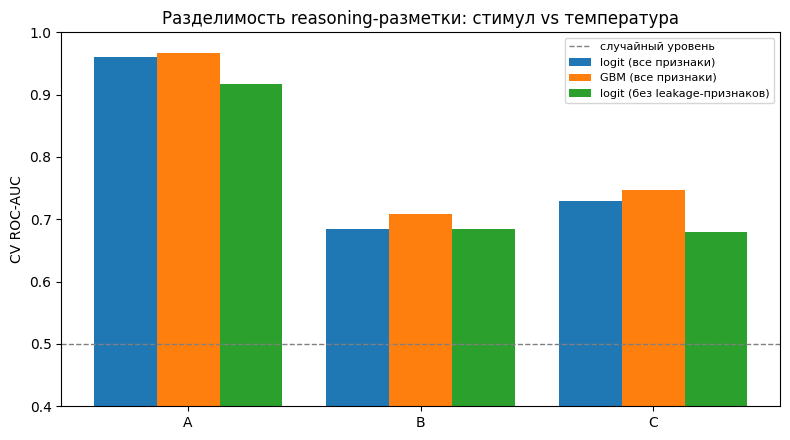

In [25]:
# 7.2 Визуализация бенчмарка
fig, ax = plt.subplots(figsize=(8, 4.5))
pooled = bench[bench.scope == 'pooled']
x = np.arange(len(pooled))
w = 0.27
ax.bar(x - w, pooled.AUC_logit, w, label='logit (все признаки)')
ax.bar(x, pooled.AUC_gbm, w, label='GBM (все признаки)')
ax.bar(x + w, pooled.AUC_logit_noleak, w, label='logit (без leakage-признаков)')
ax.axhline(0.5, color='gray', ls='--', lw=1, label='случайный уровень')
ax.set_xticks(x); ax.set_xticklabels([t.split(':')[0] for t in pooled.task])
ax.set_ylabel('CV ROC-AUC'); ax.set_ylim(0.4, 1.0)
ax.set_title('Разделимость reasoning-разметки: стимул vs температура')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## §7 — итог: стимул сдвигает reasoning сильнее, чем температура

| Задача | pooled AUC (logit) | GBM | logit без leakage |
|---|---|---|---|
| **A: incentive presence** (no_inc vs A/C, T=0.01) | **0.960** | 0.967 | **0.917** |
| **B: температура** (T=0.01 vs T=1.0, no_inc) | 0.684 | 0.709 | 0.684 |
| C: A vs C (между стимулами) | 0.730 | 0.747 | 0.679 |

1. **Ключевой паттерн пилота воспроизводится на новой разметке**: traces со стимулом
   и без отделяются почти идеально (AUC≈0.96), тогда как изменение температуры
   генерации — слабо (AUC≈0.68). Стимул входит в reasoning содержательно, а не как
   произвольный сдвиг настроек генерации.
2. **Результат не сводится к «детекции по построению»**: после исключения
   incentive_awareness и incentive_effect AUC падает лишь до 0.92 — сдвиг виден
   в содержательных категориях (signed presence), а не только в прямом упоминании стимула.
3. По моделям: incentive-AUC 0.95–1.00 у всех; temperature-AUC 0.63–0.68 у GLM/Kimi/Minimax,
   но **0.835 у Qwen3.5** — согласуется с caveat отбора §6.4 (у Qwen меньше всего валидных
   строк при T=0.01, состав выборки между температурами различается сильнее).
4. A vs C разделимы умеренно (0.73) — harsh и balanced версии стимула меняют reasoning
   в одну сторону, различаясь скорее силой, чем структурой.

**Caveat**: AUC ничего не говорит о *надёжности* категорий (§6.1) — только о том, что
разметка как вектор признаков несёт сигнал о условии генерации.

# §8. Interpretable-ML слой: аддитивность (Hassner) vs взаимодействия (Savary)

План текста курсовой предполагал SHAP/LIME поверх моделей markup→answer. Сначала —
диагностика: есть ли вообще нелинейность, которую SHAP мог бы объяснить. Сравниваем
CV-качество линейной модели и GBM на признаках §5 (+ контекст group/incentive/model).

- **Hassner**: logit = GBM (AUC 0.989 vs 0.991) → отображение reasoning→answer
  **аддитивно**, SHAP не нужен — коэффициенты §5 и есть полное объяснение.
- **Savary**: GBM > ridge (CV R² 0.558 vs 0.475) → есть взаимодействия. Для них —
  TreeSHAP как *discovery* (какие пары признаков взаимодействуют), затем
  подтверждающая OLS с явными interaction-термами и HC3 p-values.

LIME не используется: на табличных бинарных признаках нестабилен и доминируется SHAP.

In [26]:
# 8.1 Диагностика нелинейности: linear vs GBM (CV)
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

IML_FEATS = SP_COLS + NO_DIR_BINS + STYLE_BINS + ['incentive_effect_direction']

def _ctx_X(sub):
    ctx = pd.get_dummies(sub[['group_name','incentive','model_name']],
                         drop_first=True).astype(float)
    return pd.concat([sub[IML_FEATS].fillna(0).reset_index(drop=True),
                      ctx.reset_index(drop=True)], axis=1)

X_h, y_h = _ctx_X(H), H['y_bin'].values
cv_h = StratifiedKFold(5, shuffle=True, random_state=0)
auc_log = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                          X_h.values, y_h, cv=cv_h, scoring='roc_auc').mean()
auc_gbm = cross_val_score(GradientBoostingClassifier(random_state=0), X_h.values, y_h,
                          cv=cv_h, scoring='roc_auc').mean()

X_s, y_s = _ctx_X(S), S['answer_num'].values
cv_s = KFold(5, shuffle=True, random_state=0)
r2_lin = cross_val_score(make_pipeline(StandardScaler(), RidgeCV()), X_s.values, y_s,
                         cv=cv_s, scoring='r2').mean()
r2_gbm = cross_val_score(GradientBoostingRegressor(random_state=0), X_s.values, y_s,
                         cv=cv_s, scoring='r2').mean()

diag = pd.DataFrame({
    'experiment': ['Hassner (AUC)', 'Savary (R²)'],
    'linear': [auc_log, r2_lin], 'GBM': [auc_gbm, r2_gbm],
    'gap': [auc_gbm - auc_log, r2_gbm - r2_lin]})
display(diag.round(4))
display(Markdown(
    "**Hassner — аддитивен** (gap≈0): объяснение = коэффициенты §5, SHAP избыточен.  \n"
    "**Savary — нелинеен** (gap≈+0.08 R²): дальше ищем взаимодействия через TreeSHAP."))

,experiment,linear,GBM,gap
0,Hassner (AUC),0.9891,0.9913,0.0022
1,Savary (R²),0.4751,0.5581,0.0830


**Hassner — аддитивен** (gap≈0): объяснение = коэффициенты §5, SHAP избыточен.  
**Savary — нелинеен** (gap≈+0.08 R²): дальше ищем взаимодействия через TreeSHAP.

### Top-12 mean|SHAP| (Savary, GBM с контекстом)

,mean|SHAP|
group_name_public_recognition_with_social_benefit,0.1814
incentive_no_incentive,0.1116
model_name_qwen/qwen3.5-9b,0.0556
model_name_moonshotai/kimi-k2-thinking,0.0498
sp_privacy_factor,0.0436
sp_private_interests_prioritization,0.0402
sp_emotional_reasoning,0.0274
possibility_of_different_opinions,0.0272
moral_style_reasoning_present,0.0221
model_name_z-ai/glm-4.6,0.0210


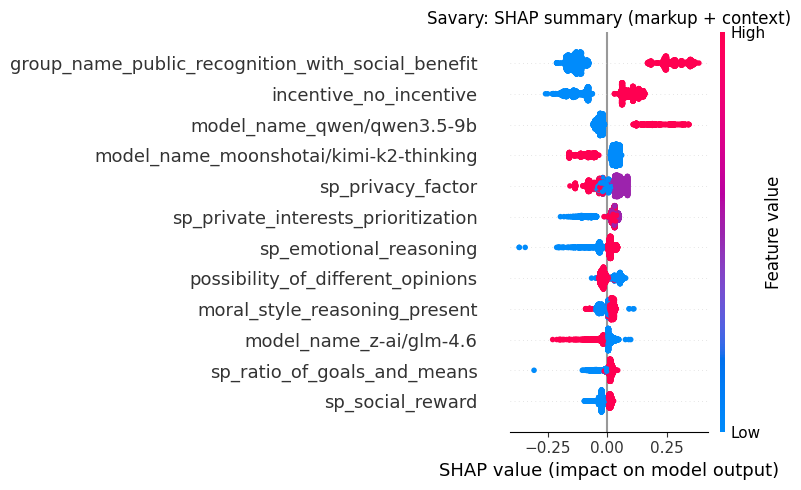

### Top-10 SHAP interaction pairs

,feat_a,feat_b,mean|SHAP interaction|
0,group_name_public_recognition_with_social_benefit,incentive_no_incentive,0.0297
1,sp_privacy_factor,incentive_no_incentive,0.0119
2,group_name_public_recognition_with_social_benefit,model_name_qwen/qwen3.5-9b,0.0095
3,incentive_no_incentive,model_name_moonshotai/kimi-k2-thinking,0.0080
4,sp_privacy_factor,group_name_public_recognition_with_social_benefit,0.0070
5,sp_emotional_reasoning,sp_privacy_factor,0.0068
6,sp_private_interests_prioritization,model_name_z-ai/glm-4.6,0.0066
7,group_name_public_recognition_with_social_benefit,model_name_moonshotai/kimi-k2-thinking,0.0060
8,sp_privacy_factor,sp_social_reward,0.0060
9,self_enhancement_causality_bin,fear_negative_evaluation_causality_bin,0.0049


In [27]:
# 8.2 Savary: TreeSHAP — глобальная важность и interaction values
import shap
import itertools

gbm_s = GradientBoostingRegressor(random_state=0).fit(X_s, y_s)
expl = shap.TreeExplainer(gbm_s)
sv = expl.shap_values(X_s)

imp = pd.Series(np.abs(sv).mean(0), index=X_s.columns).sort_values(ascending=False)
display(Markdown('### Top-12 mean|SHAP| (Savary, GBM с контекстом)'))
display(imp.head(12).round(4).to_frame('mean|SHAP|'))

fig = plt.figure(figsize=(8, 5))
shap.summary_plot(sv, X_s, max_display=12, show=False, plot_size=None)
plt.title('Savary: SHAP summary (markup + context)')
plt.tight_layout(); plt.show()

# interaction values на подвыборке (точные для деревьев, O(n·p²))
_rng = np.random.RandomState(0)
_idx = _rng.choice(len(X_s), size=min(1200, len(X_s)), replace=False)
siv = expl.shap_interaction_values(X_s.iloc[_idx])
inter = np.abs(siv).mean(0); np.fill_diagonal(inter, 0)
cols = list(X_s.columns)
pairs = sorted(((cols[i], cols[j], inter[i, j])
                for i, j in itertools.combinations(range(len(cols)), 2)),
               key=lambda t: -t[2])
top_pairs = pd.DataFrame(pairs[:10], columns=['feat_a', 'feat_b', 'mean|SHAP interaction|'])
display(Markdown('### Top-10 SHAP interaction pairs'))
display(top_pairs.round(4))

In [28]:
# 8.3 Подтверждающая OLS: явные interaction-термы (HC3)
# Top-пары SHAP (8.2), приведённые к содержательным термам
S8 = S.copy()
_ctx8 = pd.get_dummies(S8[['group_name','incentive','model_name']], drop_first=True).astype(float)
_ctx8.index = S8.index

def _col(name):
    return S8[name] if name in S8.columns else _ctx8[name]

IX_TERMS = [
    ('ix_socben_noinc', 'group_name_public_recognition_with_social_benefit', 'incentive_no_incentive'),
    ('ix_privacy_noinc', 'sp_privacy_factor', 'incentive_no_incentive'),
    ('ix_socben_qwen', 'group_name_public_recognition_with_social_benefit', 'model_name_qwen/qwen3.5-9b'),
    ('ix_noinc_kimi', 'incentive_no_incentive', 'model_name_moonshotai/kimi-k2-thinking'),
    ('ix_privacy_socben', 'sp_privacy_factor', 'group_name_public_recognition_with_social_benefit'),
    ('ix_emo_privacy', 'sp_emotional_reasoning', 'sp_privacy_factor'),
]
for name, a, b in IX_TERMS:
    S8[name] = _col(a).fillna(0).values * _col(b).fillna(0).values

_base = ' + '.join(IML_FEATS)
S8[IML_FEATS] = S8[IML_FEATS].fillna(0)
f_base = f'answer_num ~ {_base} + C(group_name) + C(incentive) + C(model_name)'
f_ix = f_base + ' + ' + ' + '.join(t[0] for t in IX_TERMS)
m_base = smf.ols(f_base, data=S8).fit(cov_type='HC3')
m_ix = smf.ols(f_ix, data=S8).fit(cov_type='HC3')

display(Markdown(f'**R²: base = {m_base.rsquared:.4f} → c interactions = {m_ix.rsquared:.4f}**'))
ix_table = pd.DataFrame({
    'term': [f'{a} × {b}' for _, a, b in IX_TERMS],
    'β': [m_ix.params[n] for n, _, _ in IX_TERMS],
    'SE': [m_ix.bse[n] for n, _, _ in IX_TERMS],
    'p_HC3': [m_ix.pvalues[n] for n, _, _ in IX_TERMS]})
display(ix_table.round(4))

**R²: base = 0.4871 → c interactions = 0.5193**

,term,β,SE,p_HC3
0,group_name_public_recognition_with_social_bene...,-0.2493,0.0284,0.0000
1,sp_privacy_factor × incentive_no_incentive,-0.1207,0.0203,0.0000
2,group_name_public_recognition_with_social_bene...,-0.3263,0.0279,0.0000
3,incentive_no_incentive × model_name_moonshotai...,-0.1752,0.0298,0.0000
4,sp_privacy_factor × group_name_public_recognit...,0.0073,0.0299,0.8074
5,sp_emotional_reasoning × sp_privacy_factor,0.0820,0.0204,0.0001


## §8 — итог: гибридный interpretable-ML слой

1. **Hassner: отображение reasoning→answer аддитивно.** GBM не превосходит логит
   (CV AUC 0.991 vs 0.989; без контекста 0.979 = 0.979). SHAP здесь объяснил бы то,
   что уже сказано коэффициентами §5 — само отсутствие нелинейности и есть результат:
   решение модели в Hassner собирается из независимых вкладов категорий.
2. **Savary: нелинейность реальна** (GBM CV R² 0.558 vs ridge 0.475) и почти вся
   состоит из **взаимодействий с контекстом**, а не markup×markup:
   - `treatment(social_benefit) × no_incentive`: β=−0.25, p<0.0001 — эхо DiD из Part 1
     (стимул модерирует treatment-эффект), теперь видимое на уровне reasoning-признаков;
   - `sp_privacy_factor × no_incentive`: β=−0.12, p<0.0001 — стимул меняет то, как
     privacy-рассуждение конвертируется в ответ;
   - единственное содержательное markup×markup: `sp_emotional_reasoning ×
     sp_privacy_factor` (β=+0.08, p=0.0001);
   - модельные взаимодействия (× qwen, × kimi) значимы — гетерогенность моделей
     проникает и в reasoning→answer слой.
3. Подтверждающая OLS: R² 0.487 → 0.519; 5 из 6 SHAP-найденных термов значимы (HC3).
4. **Методологический вывод**: SHAP использован по назначению — как *discovery*
   для interaction-структуры с последующим подтверждением в регрессии с p-values;
   LIME отвергнут (нестабилен на табличных бинарных данных), для Hassner
   interpretable-слой не нужен в принципе.

**Caveats**: категории разметки не валидированы против gold (§6.1), кроме cruelty и
overcorrection; SHAP-атрибуции на коррелированных признаках делят вклад произвольно —
поэтому выводы привязаны к подтверждающей регрессии, а не к самим SHAP-значениям.